# Bài tập Chương 6 — Lọc và làm trơn Bayes

Bài 6.1–6.6 thuộc mục 6.6, trang 106–107 của sách *Bayesian Filtering and Smoothing*, ấn bản thứ hai (2023) của Särkkä và Svensson. Trong [bản PDF của chương](../../docs/bayes_filtering_and_smoothing/Bayesian%20Filtering%20and%20Smoothing-121-137.pdf), đề bài nằm ở trang 16–17.

Chạy các ô theo thứ tự bằng kernel Jupyter Python 3 với NumPy, SciPy và Matplotlib. Có thể cài các thư viện bằng lệnh `python -m pip install ipykernel numpy scipy matplotlib`. Mọi bộ dữ liệu đều được tạo trong notebook. Bài 6.6 dùng lại dữ liệu và phân phối hậu nghiệm Kalman từ bài 6.2.

## 6.1 — Bộ lọc Kalman với nhiễu có kỳ vọng khác không

### Tóm tắt đề bài

Phương trình (6.44) cho mô hình Gaussian tuyến tính với kỳ vọng nhiễu quá trình là $\mathbf m_q$ và kỳ vọng nhiễu đo là $\mathbf m_r$.

### Mục tiêu toán học

Dùng bộ lọc Kalman affine để suy ra công thức truy hồi chính xác cho $p(\mathbf x_k\mid\mathbf y_{1:k})$.

### Suy luận toán học

Giả sử $\mathbf x_0\sim\mathcal N(\mathbf m_0,\mathbf P_0)$. Theo giả thiết của chương, nhiễu quá trình và nhiễu đo đều là nhiễu trắng, độc lập với nhau và với $\mathbf x_0$. Từ $\mathbf q_{k-1}\sim\mathcal N(\mathbf m_q,\mathbf Q)$ và $\mathbf r_k\sim\mathcal N(\mathbf m_r,\mathbf R)$, ta đưa nhiễu về kỳ vọng bằng không bằng cách đặt $\tilde{\mathbf q}_{k-1}=\mathbf q_{k-1}-\mathbf m_q$ và $\tilde{\mathbf r}_k=\mathbf r_k-\mathbf m_r$. Hiệp phương sai tương ứng vẫn là $\mathbf Q$ và $\mathbf R$. Khi đó mô hình có dạng
$$
\mathbf x_k=\mathbf A\mathbf x_{k-1}+\mathbf m_q+\tilde{\mathbf q}_{k-1},
\qquad
\mathbf y_k=\mathbf H\mathbf x_k+\mathbf m_r+\tilde{\mathbf r}_k.
$$
Đây là mô hình (6.34) với các số hạng affine $\mathbf a_{k-1}=\mathbf m_q$ và $\mathbf b_k=\mathbf m_r$. Theo Định lý 6.9, phân phối dự báo là $\mathcal N(\mathbf m^-_k,\mathbf P^-_k)$ và phân phối hậu nghiệm là $\mathcal N(\mathbf m_k,\mathbf P_k)$.

**Bước dự báo**
$$
\mathbf m^-_k=\mathbf A\mathbf m_{k-1}+\mathbf m_q,
\qquad
\mathbf P^-_k=\mathbf A\mathbf P_{k-1}\mathbf A^\mathsf T+\mathbf Q.
$$

**Bước cập nhật**
$$
\begin{aligned}
\mathbf v_k&=\mathbf y_k-(\mathbf H\mathbf m^-_k+\mathbf m_r),\
\mathbf S_k&=\mathbf H\mathbf P^-_k\mathbf H^\mathsf T+\mathbf R,\
\mathbf K_k&=\mathbf P^-_k\mathbf H^\mathsf T\mathbf S_k^{-1},\
\mathbf m_k&=\mathbf m^-_k+\mathbf K_k\mathbf v_k,\
\mathbf P_k&=\mathbf P^-_k-\mathbf K_k\mathbf S_k\mathbf K_k^\mathsf T.
\end{aligned}
$$
Phân phối dự báo của phép đo có kỳ vọng $\mathbf H\mathbf m^-_k+\mathbf m_r$ và hiệp phương sai $\mathbf S_k$.

### Nhận xét

Các số hạng tất định làm dịch kỳ vọng dự báo của trạng thái và phép đo. Công thức hiệp phương sai và hệ số Kalman giữ nguyên vì phép trừ kỳ vọng bảo toàn hiệp phương sai và tính độc lập của nhiễu.

## 6.2 — Bộ lọc Kalman cho bước đi ngẫu nhiên Gaussian

### Tóm tắt đề bài

Triển khai bộ lọc ở Ví dụ 6.7 cho mô hình bước đi ngẫu nhiên Gaussian ở Ví dụ 6.4. Mô phỏng một chuỗi trạng thái và phép đo, rồi biểu diễn phân phối lọc theo thời gian.

### Mục tiêu toán học

Tính kỳ vọng và phương sai hậu nghiệm Gaussian chính xác ở từng bước. So sánh ước lượng bằng kỳ vọng hậu nghiệm với phép đo thô.

### Suy luận toán học

Mô hình có phương trình trạng thái $x_k=x_{k-1}+q_{k-1}$ và phương trình đo $y_k=x_k+r_k$, với hai nhiễu độc lập $q_{k-1}\sim\mathcal N(0,Q)$ và $r_k\sim\mathcal N(0,R)$. Áp dụng Định lý 6.6 với $A=H=1$, ta được
$$
\begin{aligned}
m^-_k&=m_{k-1}, & P^-_k&=P_{k-1}+Q,\
v_k&=y_k-m^-_k, & S_k&=P^-_k+R,\
K_k&=P^-_k/S_k, & m_k&=m^-_k+K_k v_k,\
P_k&=P^-_k-K_k^2S_k=\frac{RP^-_k}{P^-_k+R}.
\end{aligned}
$$
Biểu thức cuối tương đương về đại số với (6.31) và tránh phép trừ hai số gần bằng nhau. Tại mỗi bước, khoảng khả tín trung tâm 95% của phân phối hậu nghiệm chính xác $\mathcal N(m_k,P_k)$ là $m_k\pm\Phi^{-1}(0.975)\sqrt{P_k}$.

### Triển khai tính toán

Dùng phương sai mô phỏng trong sách $Q=R=1$. Mô phỏng 100 phép đo với seed 1 và trạng thái đầu đã biết $x_0=0$, nên $m_0=P_0=0$. Phép đo đầu tiên ở $k=1$. Seed cố định cho quỹ đạo phù hợp để đối chiếu với lưới đề xuất ở bài 6.6.

In [1]:
%matplotlib inline

from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.linalg import cholesky
from scipy.stats import norm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})


def rmse(estimate, truth, axis=None):
    return np.sqrt(np.mean((estimate - truth) ** 2, axis=axis))


def scalar_kalman_filter(measurements, Q, R, m0, P0):
    m, P = m0, P0
    means, variances, predictive_variances, gains = np.empty((4, len(measurements)))
    for i, y in enumerate(measurements):
        m_pred = m
        P_pred = P + Q

        innovation = y - m_pred
        S = P_pred + R
        K = P_pred / S
        m = m_pred + K * innovation
        P = R * P_pred / S

        means[i], variances[i], predictive_variances[i], gains[i] = m, P, P_pred, K
    return means, variances, predictive_variances, gains


walk_steps = 100
walk_Q = walk_R = 1.0
walk_m0 = walk_P0 = 0.0
walk_t = np.arange(1, walk_steps + 1)
walk_rng = np.random.default_rng(1)
walk_states = walk_m0 + np.cumsum(walk_rng.normal(0, np.sqrt(walk_Q), walk_steps))
walk_y = walk_states + walk_rng.normal(0, np.sqrt(walk_R), walk_steps)
walk_mean, walk_var, walk_pred_var, walk_gain = scalar_kalman_filter(
    walk_y, walk_Q, walk_R, walk_m0, walk_P0
)

assert np.all(walk_var > 0)
assert np.all(walk_var < walk_pred_var)
assert np.all((walk_gain > 0) & (walk_gain < 1))
np.testing.assert_allclose(walk_pred_var, np.r_[walk_P0, walk_var[:-1]] + walk_Q)
np.testing.assert_allclose(walk_var, walk_R * walk_gain)

### Kết quả và biểu đồ

RMSE của phép đo thô = 0.9948
RMSE của bộ lọc Kalman = 0.7206


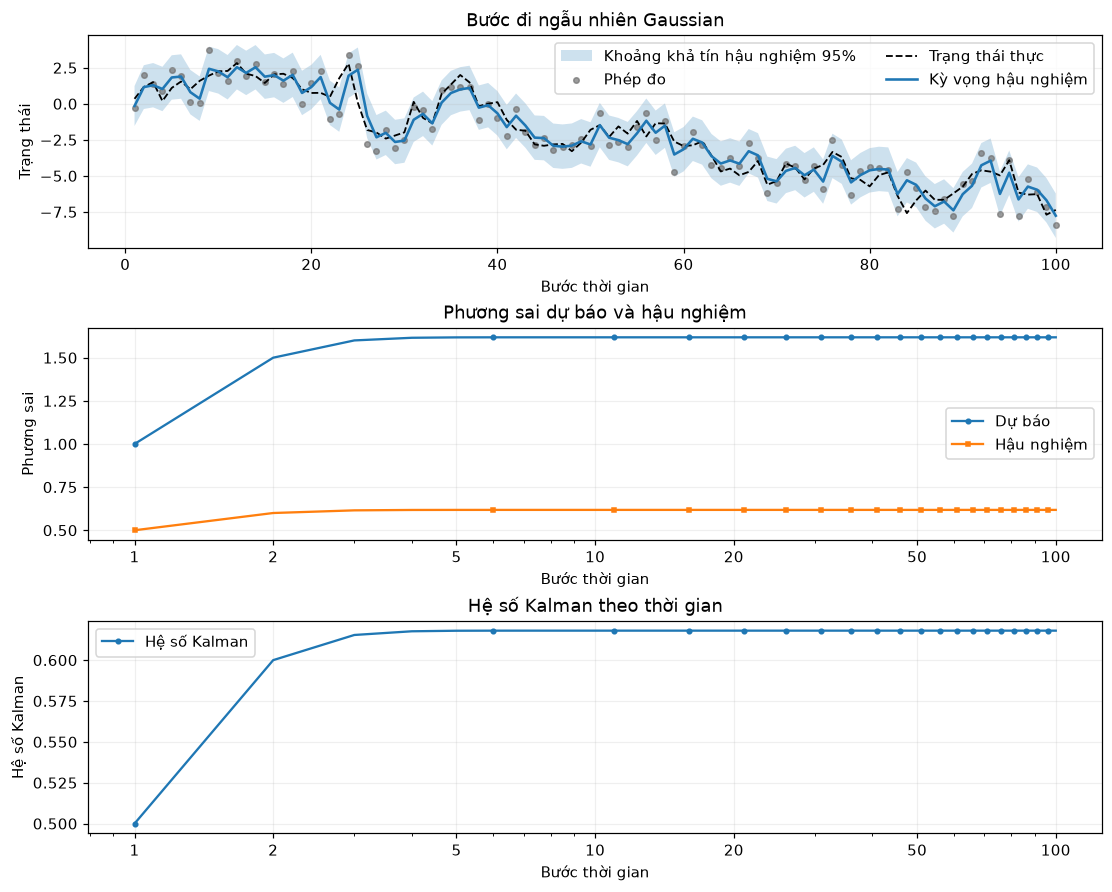

In [2]:
walk_raw_rmse = rmse(walk_y, walk_states)
walk_kf_rmse = rmse(walk_mean, walk_states)
walk_credible_radius = norm.ppf(0.975) * np.sqrt(walk_var)
print(f"RMSE của phép đo thô = {walk_raw_rmse:.4f}")
print(f"RMSE của bộ lọc Kalman = {walk_kf_rmse:.4f}")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), constrained_layout=True)
axis = axes[0]
axis.fill_between(
    walk_t, walk_mean - walk_credible_radius, walk_mean + walk_credible_radius,
    alpha=0.22, label="Khoảng khả tín hậu nghiệm 95%",
)
axis.scatter(walk_t, walk_y, color="0.45", s=13, alpha=0.7, label="Phép đo")
axis.plot(walk_t, walk_states, "k--", lw=1.2, label="Trạng thái thực")
axis.plot(walk_t, walk_mean, color="C0", lw=1.7, label="Kỳ vọng hậu nghiệm")
axis.set(title="Bước đi ngẫu nhiên Gaussian", xlabel="Bước thời gian", ylabel="Trạng thái")
axis.legend(ncol=2)

axes[1].plot(walk_t, walk_pred_var, "o-", ms=3, markevery=5, label="Dự báo")
axes[1].plot(walk_t, walk_var, "s-", ms=3, markevery=5, label="Hậu nghiệm")
axes[1].set(title="Phương sai dự báo và hậu nghiệm", xlabel="Bước thời gian", ylabel="Phương sai")
axes[1].legend()
axes[2].plot(walk_t, walk_gain, "o-", ms=3, markevery=5, label="Hệ số Kalman")
axes[2].set(title="Hệ số Kalman theo thời gian", xlabel="Bước thời gian", ylabel="Hệ số Kalman")
axes[2].legend()
for axis in axes[1:]:
    axis.set_xscale("log")
    ticks = (1, 2, 5, 10, 20, 50, 100)
    axis.set_xticks(ticks, labels=[str(tick) for tick in ticks])
plt.show()

### Nhận xét

Nhiễu quá trình làm tăng độ bất định ở bước dự báo, còn phép đo giúp giảm độ bất định ở bước cập nhật. Vì trạng thái đầu đã biết, hai phương sai và hệ số Kalman tăng ở những bước đầu rồi tiến tới giá trị ổn định dù trạng thái tiếp tục biến động. Kỳ vọng hậu nghiệm kết hợp thông tin từ quá khứ và phép đo mới, giúp giảm RMSE trong lần mô phỏng này. Cả kỳ vọng và khoảng khả tín đều dựa trên dữ liệu đến thời điểm hiện tại.

## 6.3 — Bộ lọc Kalman ở trạng thái xác lập

### Tóm tắt đề bài

Với cùng mô hình bước đi ngẫu nhiên, tìm hệ số Kalman giới hạn và công thức ước lượng với hệ số cố định. Vẽ đáp ứng tần số và xác định loại bộ lọc số.

### Mục tiêu toán học

Tìm điểm bất động Riccati thỏa điều kiện của phương sai và xác định quan hệ đầu vào–đầu ra từ $y_k$ đến $m_k$ khi bộ lọc đạt trạng thái xác lập.

### Suy luận toán học

Giả sử $Q,R>0$ như trong Ví dụ 6.4. Ánh xạ Riccati cho phương sai hậu nghiệm là $f(P)=R(P+Q)/(P+Q+R)$. Điểm bất động thỏa mãn
$$
P_\infty^2+QP_\infty-QR=0,\qquad
P_\infty=\frac{\sqrt{Q^2+4QR}-Q}{2},\qquad
P^-_\infty=P_\infty+Q.
$$
Nghiệm còn lại $(-Q-\sqrt{Q^2+4QR})/2$ âm nên không thể là phương sai. Với $P\ge0$, ta có $0<f'(P)=R^2/(P+Q+R)^2\le[R/(Q+R)]^2<1$, nên phương sai hội tụ về điểm bất động không âm duy nhất. Hệ số Kalman giới hạn và công thức truy hồi cho kỳ vọng là
$$
K_\infty=\frac{P^-_\infty}{P^-_\infty+R}=\frac{P_\infty}{R},
\qquad
m_k=a\,m_{k-1}+K_\infty y_k,\qquad a=1-K_\infty\in(0,1).
$$

Với điều kiện đầu bằng không, phép biến đổi Z cho $M(z)=a z^{-1}M(z)+K_\infty Y(z)$. Gọi $\Omega$ là tần số góc số, tính bằng radian trên mỗi mẫu.
$$
\begin{aligned}
G(z)&=\frac{M(z)}{Y(z)}=\frac{K_\infty}{1-a z^{-1}},&
G(e^{j\Omega})&=\frac{K_\infty}{1-ae^{-j\Omega}},\
|G(e^{j\Omega})|&=\frac{K_\infty}{\sqrt{1+a^2-2a\cos\Omega}},&
\angle G(e^{j\Omega})&=-\operatorname{atan2}(a\sin\Omega,1-a\cos\Omega).
\end{aligned}
$$
Cực $a$ nằm trong đường tròn đơn vị và độ lợi tại tần số 0 bằng một. Biên độ giảm trên $[0,\pi]$ và đạt $K_\infty/(2-K_\infty)$ tại tần số Nyquist. Đây là bộ lọc thông thấp IIR bậc một ổn định, tương ứng với trung bình trượt hàm mũ.

### Kết quả và biểu đồ

Đồ thị đáp ứng tần số với $Q=R=1$ là phần đề bài yêu cầu. Các đường ứng với những tỷ số $Q/R$ khác và đồ thị hội tụ là phần khảo sát bổ sung.

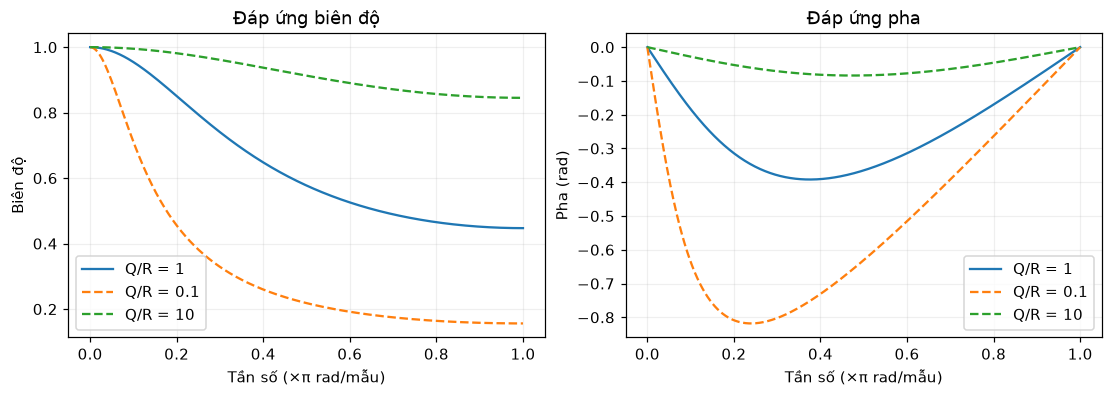

Phương sai hậu nghiệm xác lập =   0.61803399
Phương sai dự báo xác lập =  1.61803399
Hệ số Kalman xác lập =                 0.61803399


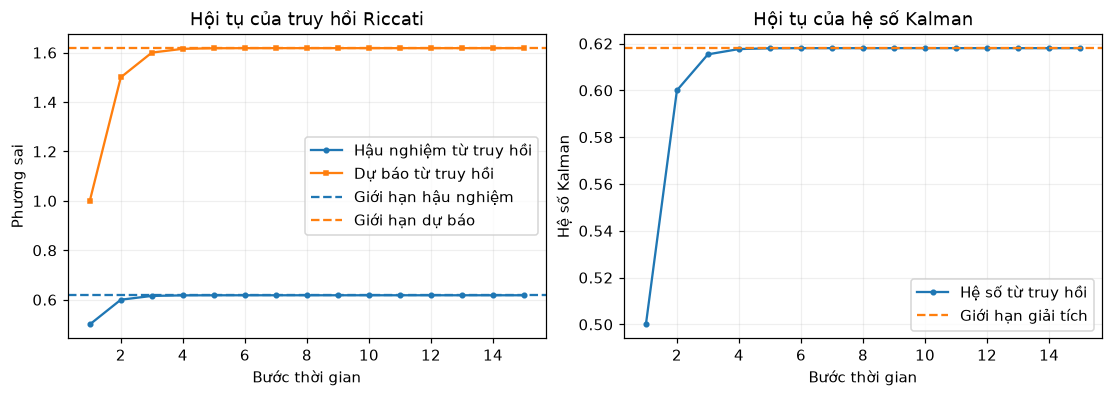

In [3]:
def steady_state_random_walk(Q, R):
    P = 2 * Q * R / (np.sqrt(Q**2 + 4 * Q * R) + Q)
    P_pred = P + Q
    return P, P_pred, P / R


steady_var, steady_pred_var, steady_gain = steady_state_random_walk(walk_Q, walk_R)
np.testing.assert_allclose(
    [walk_var[-1], walk_pred_var[-1], walk_gain[-1]],
    [steady_var, steady_pred_var, steady_gain],
    rtol=0, atol=1e-12,
)
np.testing.assert_allclose(steady_var**2 + walk_Q * steady_var, walk_Q * walk_R)

frequency = np.linspace(0, np.pi, 512)
ratios = (1.0, 0.1, 10.0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ratio in ratios:
    _, _, gain = steady_state_random_walk(ratio, 1.0)
    response = gain / (1 - (1 - gain) * np.exp(-1j * frequency))
    np.testing.assert_allclose([abs(response[0]), abs(response[-1])], [1, gain / (2 - gain)])
    style = "-" if ratio == 1.0 else "--"
    axes[0].plot(frequency / np.pi, abs(response), style, label=f"Q/R = {ratio:g}")
    axes[1].plot(frequency / np.pi, np.angle(response), style, label=f"Q/R = {ratio:g}")

axes[0].set(title="Đáp ứng biên độ", xlabel="Tần số (×π rad/mẫu)", ylabel="Biên độ")
axes[1].set(title="Đáp ứng pha", xlabel="Tần số (×π rad/mẫu)", ylabel="Pha (rad)")
for axis in axes:
    axis.legend()
plt.show()

print(f"Phương sai hậu nghiệm xác lập =   {steady_var:.8f}")
print(f"Phương sai dự báo xác lập =  {steady_pred_var:.8f}")
print(f"Hệ số Kalman xác lập =                 {steady_gain:.8f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
early = slice(0, 15)
axes[0].plot(walk_t[early], walk_var[early], "o-", ms=3, label="Hậu nghiệm từ truy hồi")
axes[0].plot(walk_t[early], walk_pred_var[early], "s-", ms=3, label="Dự báo từ truy hồi")
axes[0].axhline(steady_var, ls="--", color="C0", label="Giới hạn hậu nghiệm")
axes[0].axhline(steady_pred_var, ls="--", color="C1", label="Giới hạn dự báo")
axes[0].set(title="Hội tụ của truy hồi Riccati", xlabel="Bước thời gian", ylabel="Phương sai")
axes[0].legend()
axes[1].plot(walk_t[early], walk_gain[early], "o-", ms=3, label="Hệ số từ truy hồi")
axes[1].axhline(steady_gain, ls="--", color="C1", label="Giới hạn giải tích")
axes[1].set(title="Hội tụ của hệ số Kalman", xlabel="Bước thời gian", ylabel="Hệ số Kalman")
axes[1].legend()
plt.show()

### Nhận xét

Khi $Q/R$ tăng, $K_\infty$ tăng và cực dịch về 0. Bộ lọc đặt trọng số lớn hơn lên phép đo mới và giữ lại nhiều thành phần tần số cao hơn. Tỷ số nhỏ hơn làm cực dịch về 1, kéo dài ảnh hưởng của các phép đo cũ và tăng mức suy giảm ở tần số cao.

## 6.4 — Bộ lọc Kalman cho hệ dao động có nhiễu

### Tóm tắt đề bài

Hệ dao động có hai thành phần trạng thái, trong đó chỉ thành phần thứ nhất được đo trực tiếp. Dùng mô hình (6.45) và dữ liệu mô phỏng chính thức để so sánh bộ lọc Kalman với phương pháp đối chứng.

### Mục tiêu toán học

Ước lượng tuần tự cả hai thành phần. Tính RMSE riêng cho từng thành phần và RMSE gộp trên cùng dữ liệu.

### Suy luận toán học

Trạng thái $\mathbf x_k=(x_{1,k},x_{2,k})^\mathsf T\in\mathbb R^2$ gồm tín hiệu và đạo hàm của nó. Ma trận $2\times2$ ký hiệu $\mathbf A$ chuyển trạng thái qua một khoảng lấy mẫu. Ma trận hiệp phương sai $2\times2$ ký hiệu $\mathbf Q$ mô tả nhiễu quá trình tích lũy. Hàng quan sát $\mathbf H=(1\;0)$ có kích thước $1\times2$, còn $R=0.1$ là phương sai nhiễu đo. Đặt $\omega=1/2$, $q^c=0.01$, $c=\cos\omega$ và $s=\sin\omega$.
$$
\begin{aligned}
\mathbf x_k&=\mathbf A\mathbf x_{k-1}+\mathbf q_{k-1},
& y_k&=\mathbf H\mathbf x_k+r_k,\
\mathbf A&=\begin{pmatrix}c&s/\omega\\-\omega s&c\end{pmatrix},
&\mathbf Q&=\frac{q^c}{2}
\begin{pmatrix}
(\omega-cs)/\omega^3&s^2/\omega^2\\
s^2/\omega^2&(\omega+cs)/\omega
\end{pmatrix}.
\end{aligned}
$$
Hai nhiễu $\mathbf q_{k-1}\sim\mathcal N(\mathbf 0,\mathbf Q)$ và $r_k\sim\mathcal N(0,R)$ là nhiễu trắng độc lập. Với $k\ge1$, áp dụng Định lý 6.6 để tính $\mathbf m^-_k=\mathbf A\mathbf m_{k-1}$ và $\mathbf P^-_k=\mathbf A\mathbf P_{k-1}\mathbf A^\mathsf T+\mathbf Q$. Phương sai của sai số dự báo phép đo là $S_k=P^-_{11,k}+R$. Hệ số Kalman có dạng
$$
\mathbf K_k=\frac{1}{S_k}\begin{pmatrix}P^-_{11,k}\\P^-_{21,k}\end{pmatrix}.
$$
Với sai số dự báo phép đo $v_k=y_k-\mathbf H\mathbf m^-_k$, kỳ vọng được cập nhật theo $\mathbf m_k=\mathbf m^-_k+\mathbf K_kv_k$. Mã dùng dạng Joseph, tương đương về đại số với công thức cập nhật hiệp phương sai của Định lý 6.6.
$$
\mathbf P_k=(\mathbf I-\mathbf K_k\mathbf H)\mathbf P^-_k(\mathbf I-\mathbf K_k\mathbf H)^\mathsf T
 +\mathbf K_k R\mathbf K_k^\mathsf T.
$$
Thành phần thứ hai của hệ số Kalman phụ thuộc vào hiệp phương sai chéo dự báo do động lực học và nhiễu quá trình tạo ra. Ma trận kiểm tra tính quan sát gồm hai hàng $\mathbf H$ và $\mathbf H\mathbf A$, có định thức $s/\omega\ne0$. Vì vậy, các phép đo liên tiếp trong trường hợp không nhiễu chứa thông tin về cả hai thành phần.

### Triển khai tính toán

Notebook Python chính thức dùng 100 mẫu, seed 31415926, trạng thái đầu thực $(0,0.1)^\mathsf T$ và phân phối tiên nghiệm $\mathcal N((0,1)^\mathsf T,\mathbf I_2)$ cho bộ ước lượng. Thành phần thứ hai của phương pháp đối chứng là sai phân lùi $y_k-y_{k-1}$, với giá trị phép đo trước đó quy ước bằng 0 tại $k=0$. Đề in mô tả trung bình có trọng số của các sai phân. Ở đây dùng cách tính đối chứng của notebook chính thức và giữ thứ tự lấy mẫu xen kẽ nhiễu đo với nhiễu quá trình. Dữ liệu có phép đo ở $k=0$, nên bước cập nhật Kalman đầu tiên dùng trực tiếp phân phối tiên nghiệm. [Notebook Exercise6_4.ipynb chính thức](https://github.com/EEA-sensors/Bayesian-Filtering-and-Smoothing/blob/main/python/exercises/Exercise6_4.ipynb).

In [4]:
res_omega, res_qc, res_R = 0.5, 0.01, 0.1
cos_w, sin_w = np.cos(res_omega), np.sin(res_omega)
res_A = np.array([[cos_w, sin_w / res_omega], [-res_omega * sin_w, cos_w]])
cross = sin_w**2 / res_omega**2
res_Q = 0.5 * res_qc * np.array([
    [(res_omega - cos_w * sin_w) / res_omega**3, cross],
    [cross, (res_omega + cos_w * sin_w) / res_omega],
])
res_H = np.array([[1., 0.]])
res_identity = np.eye(2)
assert res_A.shape == res_Q.shape == (2, 2) and res_H.shape == (1, 2)
np.testing.assert_allclose(res_Q, res_Q.T, atol=1e-12)
assert np.min(np.linalg.eigvalsh(res_Q)) > 0
assert np.linalg.matrix_rank(np.vstack([res_H, res_H @ res_A])) == 2

res_steps = 100
res_t = np.arange(res_steps)
res_truth = np.empty((res_steps, 2))
res_y = np.empty(res_steps)
res_truth[0] = [0., 0.1]
res_process_factor = cholesky(res_Q, lower=True)
# Dùng cùng bộ sinh số ngẫu nhiên như bản chính thức, lấy nhiễu đo trước nhiễu quá trình.
res_rng = np.random.RandomState(31415926)
for k in res_t:
    res_y[k] = (res_H @ res_truth[k]).item() + np.sqrt(res_R) * res_rng.standard_normal()
    next_state = res_A @ res_truth[k] + res_process_factor @ res_rng.standard_normal(2)
    if k + 1 < res_steps:
        res_truth[k + 1] = next_state

res_m0 = np.array([0., 1.])
res_baseline = np.column_stack([res_y, np.diff(res_y, prepend=res_m0[0])])
res_mean = np.empty_like(res_truth)
res_cov = np.empty((res_steps, 2, 2))
res_gain = np.empty_like(res_truth)
m, P = res_m0.copy(), res_identity.copy()
for k, y in enumerate(res_y):
    if k == 0:
        m_pred, P_pred = m, P
    else:
        m_pred = res_A @ m
        P_pred = res_A @ P @ res_A.T + res_Q

    innovation = y - (res_H @ m_pred).item()
    S = (res_H @ P_pred @ res_H.T).item() + res_R
    K = (P_pred @ res_H.T) / S
    m = m_pred + K[:, 0] * innovation
    correction = res_identity - K @ res_H
    P = correction @ P_pred @ correction.T + res_R * (K @ K.T)

    np.testing.assert_allclose(P, P_pred - S * (K @ K.T), rtol=1e-12, atol=1e-12)
    res_mean[k], res_cov[k], res_gain[k] = m, P, K[:, 0]

np.testing.assert_allclose(res_cov, res_cov.swapaxes(1, 2), atol=1e-12)
assert np.min(np.linalg.eigvalsh(res_cov)) >= -1e-12
assert res_gain[0, 1] == 0 and np.any(np.abs(res_gain[1:, 1]) > 1e-12)

### Kết quả và biểu đồ

Bộ ước lượng             Tín hiệu      Đạo hàm       Gộp
Đối chứng chính thức       0.3429       0.4901    0.4229
Bộ lọc Kalman              0.2184       0.1819    0.2010


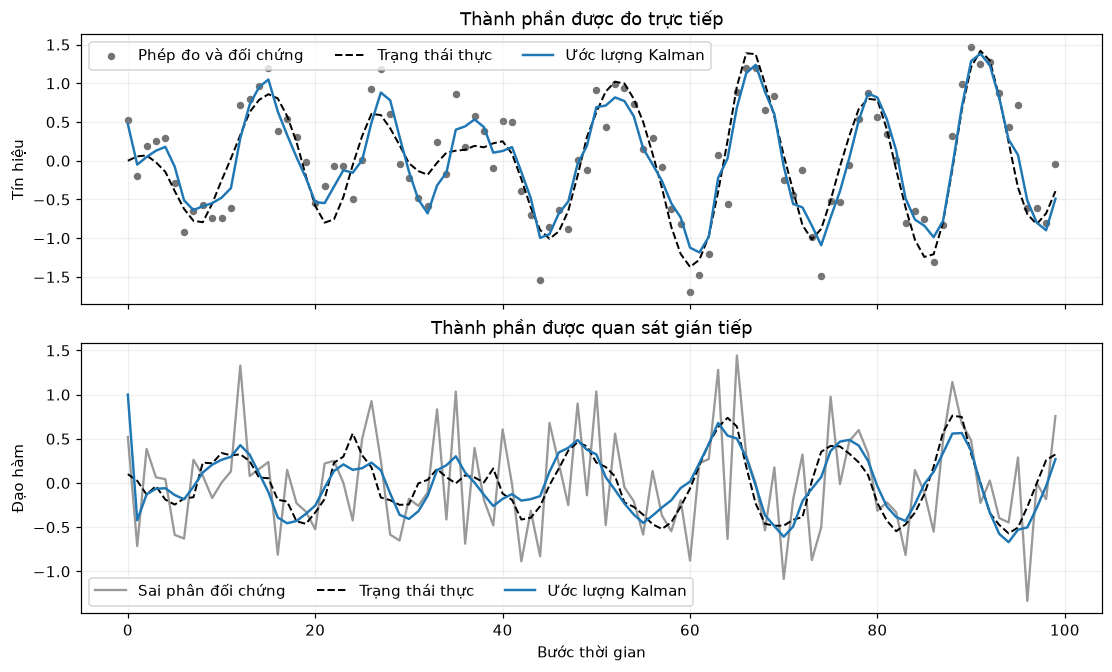

In [5]:
res_baseline_rmse = rmse(res_baseline, res_truth, axis=0)
res_kf_rmse = rmse(res_mean, res_truth, axis=0)
res_baseline_pooled = rmse(res_baseline, res_truth)
res_kf_pooled = rmse(res_mean, res_truth)
print(f"{'Bộ ước lượng':<23} {'Tín hiệu':>9} {'Đạo hàm':>12} {'Gộp':>9}")
for label, component, pooled in [
    ("Đối chứng chính thức", res_baseline_rmse, res_baseline_pooled),
    ("Bộ lọc Kalman", res_kf_rmse, res_kf_pooled),
]:
    print(f"{label:<23} {component[0]:9.4f} {component[1]:12.4f} {pooled:9.4f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
axes[0].scatter(res_t, res_y, color="0.45", s=15, label="Phép đo và đối chứng")
axes[1].plot(res_t, res_baseline[:, 1], color="0.5", alpha=0.8, label="Sai phân đối chứng")
for index, axis in enumerate(axes):
    axis.plot(res_t, res_truth[:, index], "k--", lw=1.3, label="Trạng thái thực")
    axis.plot(res_t, res_mean[:, index], lw=1.6, color="C0", label="Ước lượng Kalman")
    axis.legend(ncol=3)
axes[0].set(title="Thành phần được đo trực tiếp", ylabel="Tín hiệu")
axes[1].set(title="Thành phần được quan sát gián tiếp", xlabel="Bước thời gian", ylabel="Đạo hàm")
plt.show()

### Nhận xét

Ước lượng đạo hàm được hiệu chỉnh nhờ $P^-_{21,k}$ và dự báo qua $\mathbf A$. Khi lấy hiệu hai phép đo liên tiếp, phương pháp đối chứng cộng ảnh hưởng của hai nhiễu đo độc lập, làm phương sai nhiễu của mỗi sai phân sau bước đầu bằng $2R$. Bộ lọc Kalman kết hợp động lực học và độ bất định của phép đo, cho RMSE thấp hơn ở cả hai thành phần trên bộ dữ liệu này.

## 6.5 — Lọc Bayes cho mô hình Markov ẩn nhị phân

### Tóm tắt đề bài

Trạng thái ẩn và phép đo đều nhận giá trị trong $\{1,2\}$. Xác suất chuyển trạng thái là $\rho_{1,2}=0.2$ và $\rho_{2,1}=0.1$, với phân phối tiên nghiệm $\mathbf p_0=(0.5,0.5)^\mathsf T$. So sánh cách lấy phép đo làm dự đoán với bộ lọc HMM qua 100 lần mô phỏng độc lập, mỗi lần 100 bước.

### Mục tiêu toán học

Kiểm tra các ma trận của mô hình, suy ra công thức truy hồi hậu nghiệm chính xác và đo sai số phân loại theo quy tắc MAP biên.

### Suy luận toán học

Trong ma trận chuyển trạng thái $\boldsymbol\Pi$, hàng là trạng thái trước và cột là trạng thái hiện tại. Mỗi phần tử đường chéo bằng một trừ xác suất chuyển sang trạng thái kia. Trong ma trận phát xạ $\mathbf O$, hàng là trạng thái hiện tại và cột là phép đo. Mô hình chính dùng phương trình (6.46).
$$
\boldsymbol\Pi=\begin{pmatrix}0.8&0.2\\0.1&0.9\end{pmatrix},
\qquad
\mathbf O=\begin{pmatrix}0.7&0.3\\0.3&0.7\end{pmatrix}.
$$
Các phần tử của mỗi hàng trong cả hai ma trận đều không âm và có tổng bằng một. Theo (6.46), $\Pr(y_k=x_k\mid x_k)=0.7$ với cả hai trạng thái, nên sai số kỳ vọng của quy tắc $\hat x_k=y_k$ bằng $0.3$ ở mọi bước. Phần mô tả của đề ghi $\Pr(y_k=x_k\mid x_k)=0.3$. Nếu dùng xác suất đó, ta có $\mathbf O_{\rm prose}=\left(\begin{smallmatrix}0.3&0.7\\0.7&0.3\end{smallmatrix}\right)$ và sai số bằng $0.7$ cho quy tắc đối chứng $\hat x_k=y_k$. Khi ấy, quy tắc đảo nhãn $\hat x_k=3-y_k$ có sai số $0.3$. Hai mô hình đo tương ứng với nhau qua phép đổi nhãn này.

Hệ quả 6.10 chuyển tích phân dự báo và tích phân chuẩn hóa thành tổng. Theo Hệ quả 6.11, với xác suất trạng thái viết dưới dạng vectơ cột, ta có
$$
p^-_{j,k}=\sum_i\Pi_{ij}p_{i,k-1},
\qquad
p_{j,k}=\frac{O_{j,y_k}p^-_{j,k}}{\sum_i O_{i,y_k}p^-_{i,k}}.
$$
Bước dự báo cũng có thể viết dưới dạng $\mathbf p_k^-=\boldsymbol\Pi^\mathsf T\mathbf p_{k-1}$. Ước lượng MAP biên $\hat x_k=\arg\max_j p_{j,k}$ cực tiểu hóa tổn thất 0–1 có điều kiện tại bước $k$. Nếu hai xác suất bằng nhau, chọn nhãn nhỏ hơn.

### Triển khai tính toán

Mỗi lần mô phỏng lấy $x_0$ từ phân phối tiên nghiệm. Mã dùng nhãn $1,2$ và chỉ trừ một khi truy cập mảng. Mỗi lần mô phỏng dùng một luồng số ngẫu nhiên riêng.

In [6]:
hmm_transition = np.array([[0.8, 0.2], [0.1, 0.9]])
hmm_emission = np.array([[0.7, 0.3], [0.3, 0.7]])
hmm_prior = np.array([0.5, 0.5])
hmm_labels = np.array([1, 2])
assert np.isclose(hmm_prior.sum(), 1)
for matrix in (hmm_transition, hmm_emission):
    assert matrix.shape == (2, 2) and np.all(matrix >= 0)
    np.testing.assert_allclose(matrix.sum(axis=1), 1)
np.testing.assert_allclose([hmm_transition[0, 1], hmm_transition[1, 0]], [0.2, 0.1])
np.testing.assert_allclose(np.diag(hmm_emission), 0.7)


def simulate_binary_hmm(steps, rng):
    states = np.empty(steps, dtype=int)
    observations = np.empty(steps, dtype=int)
    previous = rng.choice(hmm_labels, p=hmm_prior)
    for i in range(steps):
        state = rng.choice(hmm_labels, p=hmm_transition[previous - 1])
        observations[i] = rng.choice(hmm_labels, p=hmm_emission[state - 1])
        states[i] = state
        previous = state
    return states, observations


def filter_binary_hmm(observations, emission):
    probabilities = np.empty((len(observations), 2))
    p = hmm_prior.copy()
    for i, y in enumerate(observations):
        p_pred = hmm_transition.T @ p
        weights = emission[:, y - 1] * p_pred
        p = weights / weights.sum()
        probabilities[i] = p
    return probabilities


hmm_runs, hmm_steps = 100, 100
hmm_truth = np.empty((hmm_runs, hmm_steps), dtype=int)
hmm_y = np.empty_like(hmm_truth)
hmm_posterior = np.empty((hmm_runs, hmm_steps, 2))
for run, seed in enumerate(np.random.SeedSequence(605).spawn(hmm_runs)):
    hmm_truth[run], hmm_y[run] = simulate_binary_hmm(hmm_steps, np.random.default_rng(seed))
    hmm_posterior[run] = filter_binary_hmm(hmm_y[run], hmm_emission)

assert np.all(hmm_posterior >= 0)
np.testing.assert_allclose(hmm_posterior.sum(axis=-1), 1, atol=1e-14, rtol=0)
np.testing.assert_allclose(
    filter_binary_hmm(3 - hmm_y[0], hmm_emission[:, ::-1]), hmm_posterior[0]
)
hmm_map = hmm_labels[np.argmax(hmm_posterior, axis=-1)]

### Kết quả và biểu đồ

Lần mô phỏng đầu tiên (đối chứng / MAP) = 30.0% / 25.0%
Trung bình 100 lần mô phỏng (đối chứng / MAP) = 30.24% / 25.22%
Sai số lý thuyết khi dùng trực tiếp phép đo theo (6.46) = 30.0%


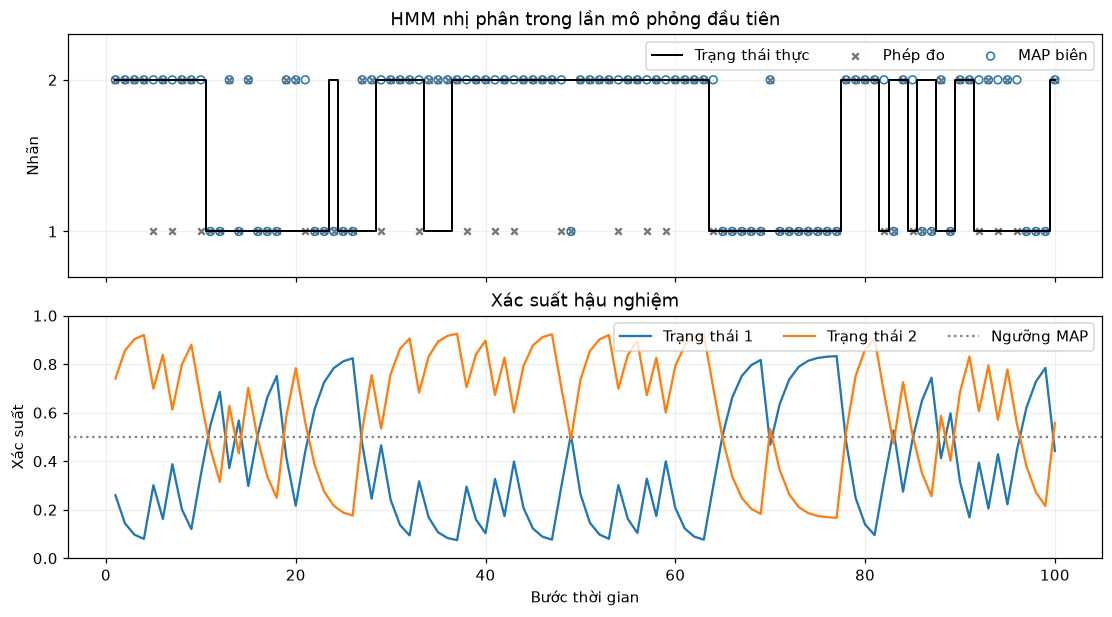

In [7]:
hmm_baseline_by_run = (hmm_y != hmm_truth).mean(axis=1)
hmm_map_by_run = (hmm_map != hmm_truth).mean(axis=1)
hmm_baseline_error = hmm_baseline_by_run.mean()
hmm_map_error = hmm_map_by_run.mean()
print(f"Lần mô phỏng đầu tiên (đối chứng / MAP) = {hmm_baseline_by_run[0]:.1%} / {hmm_map_by_run[0]:.1%}")
print(f"Trung bình {hmm_runs} lần mô phỏng (đối chứng / MAP) = {hmm_baseline_error:.2%} / {hmm_map_error:.2%}")
print(f"Sai số lý thuyết khi dùng trực tiếp phép đo theo (6.46) = {1 - hmm_emission[0, 0]:.1%}")

hmm_t = np.arange(1, hmm_steps + 1)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, constrained_layout=True)
axes[0].step(hmm_t, hmm_truth[0], where="mid", color="k", lw=1.3, label="Trạng thái thực")
axes[0].scatter(hmm_t, hmm_y[0], color="0.45", s=18, marker="x", label="Phép đo")
axes[0].scatter(
    hmm_t, hmm_map[0], s=26, facecolors="none", edgecolors="C0", label="MAP biên",
)
axes[0].set(title="HMM nhị phân trong lần mô phỏng đầu tiên", ylabel="Nhãn", yticks=[1, 2], ylim=(0.7, 2.3))
axes[0].legend(ncol=3)
for i, label in enumerate(hmm_labels):
    axes[1].plot(hmm_t, hmm_posterior[0, :, i], label=f"Trạng thái {label}")
axes[1].axhline(0.5, ls=":", color="0.5", label="Ngưỡng MAP")
axes[1].set(title="Xác suất hậu nghiệm", xlabel="Bước thời gian", ylabel="Xác suất", ylim=(0, 1))
axes[1].legend(ncol=3)
plt.show()

### Nhận xét

Chuỗi Markov có xu hướng duy trì trạng thái hiện tại, nên xác suất dự báo có thể giữ nguyên ước lượng khi một phép đo riêng lẻ gợi ý trạng thái khác. Qua 100 lần mô phỏng, quy tắc MAP biên có sai số phân loại trung bình nhỏ hơn quy tắc dùng trực tiếp phép đo. Công thức truy hồi hậu nghiệm là chính xác với HMM đã chọn. Các tỷ lệ sai số báo cáo được ước lượng bằng mô phỏng Monte Carlo.

## 6.6 — Lọc Bayes trên lưới hữu hạn

### Tóm tắt đề bài

Xấp xỉ bộ lọc Bayes của bước đi ngẫu nhiên Gaussian bằng 1.000 ô bằng nhau trên miền $[-10,10]$ mà đề gợi ý. Đối chiếu với nghiệm Kalman chính xác ở bài 6.2.

### Mục tiêu toán học

Rời rạc hóa tích phân dự báo, theo dõi khối lượng xác suất hậu nghiệm đã chuẩn hóa, rồi so sánh phân phối, mômen, RMSE và thời gian chạy trên cùng chuỗi phép đo.

### Suy luận toán học

Ký hiệu $f_k(x)=p(x_k=x\mid y_{1:k})$ và $f_k^-(x)=p(x_k=x\mid y_{1:k-1})$. Gọi $\varphi_V$ là mật độ Gaussian có kỳ vọng bằng không và phương sai $V$. Theo Định lý 6.5,
$$
f_k^-(x)=\int_{\mathbb R}\varphi_Q(x-u)f_{k-1}(u)\,du,\qquad
f_k(x)=\frac{\varphi_R(y_k-x)f_k^-(x)}
{\int_{\mathbb R}\varphi_R(y_k-z)f_k^-(z)\,dz}.
$$
Chia $[a,b]$ thành $N$ ô đều nhau. Ô $I_i$ có độ rộng $h=(b-a)/N$ và trung điểm $\xi_i=a+(i-\tfrac12)h$. Khối lượng xác suất trong ô là $p_{i,k}\approx h f_k(\xi_i)$, nên $p_{i,k}/h$ là độ cao của mật độ biểu diễn trên đồ thị. Dùng quy tắc trung điểm theo trạng thái trước rồi đổi mật độ dự báo thành khối lượng xác suất theo ô, ta được ma trận chưa chuẩn hóa $B_{ij}=h\varphi_Q(\xi_j-\xi_i)$. Mỗi hàng ứng với một ô xuất phát.
$$
T_{ij}=\frac{B_{ij}}{\sum_{\ell=1}^N B_{i\ell}},\qquad
p^-_{j,k}=\sum_i T_{ij}p_{i,k-1},\qquad
p_{j,k}=\frac{\varphi_R(y_k-\xi_j)p^-_{j,k}}
{\sum_i\varphi_R(y_k-\xi_i)p^-_{i,k}}.
$$
Chuẩn hóa từng hàng tạo ra chuyển tiếp rời rạc với điều kiện trạng thái vẫn nằm trong lưới ở bước đó. Gần biên, cách làm này thay đổi mô hình dự báo vì phần xác suất ngoài miền bị loại và phần còn lại được chuẩn hóa lại. Hiệu ứng biên vẫn tồn tại khi $h\to0$ với hai đầu mút cố định. Trạng thái đầu đã biết có toàn bộ khối lượng xác suất tại $x_0=0$, nên ở $k=1$ ta tính trực tiếp $h\varphi_Q(\xi_j-x_0)$ rồi chuẩn hóa trên lưới.

Xấp xỉ kỳ vọng hậu nghiệm bằng trung điểm cho $\hat m_k=\sum_j p_{j,k}\xi_j$ và phương sai tương ứng là $\hat P_k=\sum_j p_{j,k}(\xi_j-\hat m_k)^2$. Để so sánh phân phối, tích phân mật độ Gaussian chính xác trên cùng các ô và thêm một nhóm cho phần xác suất ngoài $[a,b]$. Khoảng cách biến thiên toàn phần (TV) trên các ô bằng một nửa tổng độ lệch tuyệt đối giữa các xác suất, kể cả nhóm ngoài miền.

### Triển khai tính toán

Dùng $Q$, $R$, điều kiện đầu và dữ liệu từ bài 6.2. Bước dự báo trên lưới dùng ma trận đặc, với chi phí tính toán $O(N^2)$ mỗi bước và bộ nhớ $O(N^2)$ cho ma trận chuyển tiếp. Bộ lọc Kalman vô hướng có chi phí tính toán và bộ nhớ làm việc không đổi ở mỗi bước nếu bỏ qua phần lưu lịch sử kết quả.

In [8]:
def midpoint_grid(lower, upper, count, Q):
    edges = np.linspace(lower, upper, count + 1)
    width = (upper - lower) / count
    centers = (edges[:-1] + edges[1:]) / 2
    differences = centers[None, :] - centers[:, None]
    transition = width * norm.pdf(differences, scale=np.sqrt(Q))
    transition /= transition.sum(axis=1, keepdims=True)
    return edges, centers, width, transition


def grid_random_walk_filter(measurements, centers, width, transition, Q, R, x0):
    first_prediction = width * norm.pdf(centers, loc=x0, scale=np.sqrt(Q))
    first_prediction /= first_prediction.sum()
    history = np.empty((len(measurements), len(centers)))
    means = np.empty(len(measurements))
    variances = np.empty(len(measurements))
    posterior = None
    for i, y in enumerate(measurements):
        if i == 0:
            prediction = first_prediction
        else:
            prediction = np.einsum("i,ij->j", posterior, transition)
        log_likelihood = -(y - centers) ** 2 / (2 * R)
        weights = prediction * np.exp(log_likelihood - log_likelihood.max())
        normalizer = weights.sum()
        if normalizer <= 0 or not np.isfinite(normalizer):
            raise FloatingPointError("Bước cập nhật trên lưới cho tổng khối lượng hậu nghiệm không hợp lệ")
        posterior = weights / normalizer
        history[i] = posterior
        means[i] = posterior @ centers
        variances[i] = posterior @ (centers - means[i]) ** 2
    return history, means, variances


def grid_comparison(lower, upper, count, repeats=3):
    build_times, filter_times = [], []
    for _ in range(repeats):
        start = perf_counter()
        edges, centers, width, transition = midpoint_grid(lower, upper, count, walk_Q)
        build_times.append(perf_counter() - start)

        start = perf_counter()
        masses, means, variances = grid_random_walk_filter(
            walk_y, centers, width, transition, walk_Q, walk_R, walk_m0
        )
        filter_times.append(perf_counter() - start)

    assert transition.shape == (count, count)
    assert np.all(transition >= 0) and np.all(masses >= 0) and np.all(variances >= 0)
    np.testing.assert_allclose(transition.sum(axis=1), 1, rtol=0, atol=1e-12)
    np.testing.assert_allclose(masses.sum(axis=1), 1, rtol=0, atol=1e-12)
    standardized = (edges[None, :] - walk_mean[:, None]) / np.sqrt(walk_var[:, None])
    exact_bin_masses = np.diff(norm.cdf(standardized), axis=1)
    exact_outside = norm.cdf(standardized[:, 0]) + norm.sf(standardized[:, -1])
    np.testing.assert_allclose(exact_bin_masses.sum(axis=1) + exact_outside, 1, atol=1e-12)
    binned_tv = 0.5 * (np.abs(masses - exact_bin_masses).sum(axis=1) + exact_outside)
    return {
        "edges": edges,
        "width": width,
        "masses": masses,
        "means": means,
        "variances": variances,
        "rmse": rmse(means, walk_states),
        "max_mean_error": np.max(np.abs(means - walk_mean)),
        "max_var_error": np.max(np.abs(variances - walk_var)),
        "max_outside": exact_outside.max(),
        "max_tv": binned_tv.max(),
        "build_ms": 1000 * median(build_times),
        "filter_ms": 1000 * median(filter_times),
    }


grid_main = grid_comparison(-10, 10, 1000)
kalman_times = []
for _ in range(3):
    start = perf_counter()
    scalar_kalman_filter(walk_y, walk_Q, walk_R, walk_m0, walk_P0)
    kalman_times.append(perf_counter() - start)
kalman_ms = 1000 * median(kalman_times)

### Kết quả và biểu đồ

Đối chiếu kết quả trên cả 100 bước và vẽ phân phối ở bốn bước đại diện. Báo cáo trung vị thời gian của ba lần chạy trên cùng máy, bỏ qua thời gian kiểm tra và vẽ hình. Thời gian dựng lưới được đo riêng với thời gian chạy bộ lọc.

Phương pháp                 RMSE  Dựng lưới (ms) Chạy lọc (ms)
Kalman chính xác        0.720553               —         0.032
Lưới N = 1000           0.720685          19.093        16.940
Độ lệch tuyệt đối lớn nhất của kỳ vọng hậu nghiệm = 5.417e-03
Độ lệch tuyệt đối lớn nhất của phương sai hậu nghiệm = 1.047e-02
TV lớn nhất trên các ô = 3.650e-03
Xác suất hậu nghiệm chính xác lớn nhất ngoài [-10, 10] = 2.233e-03


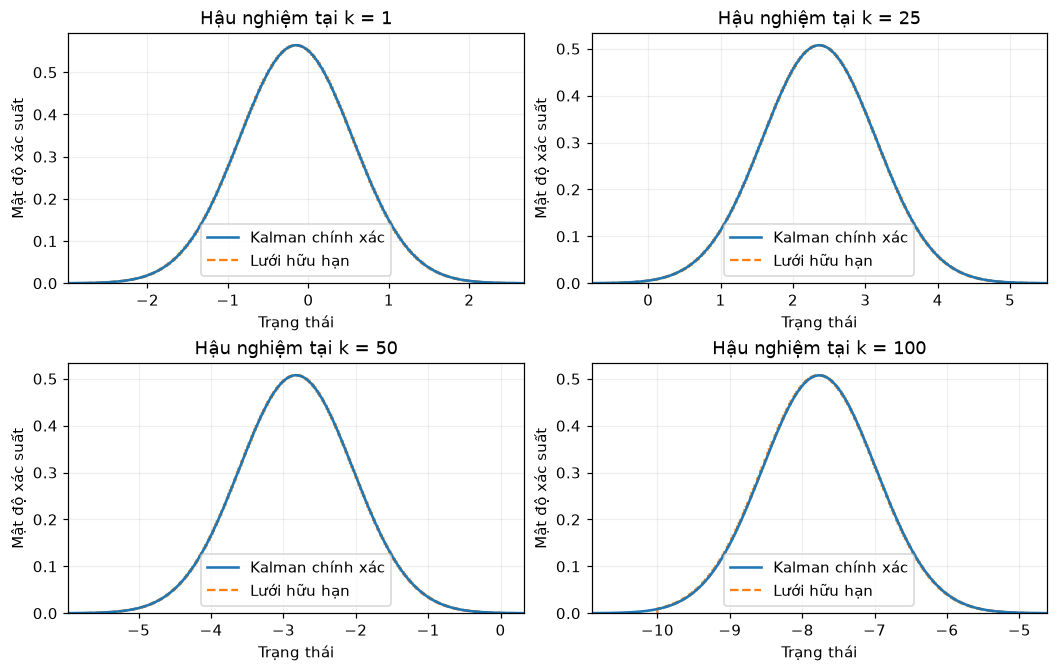

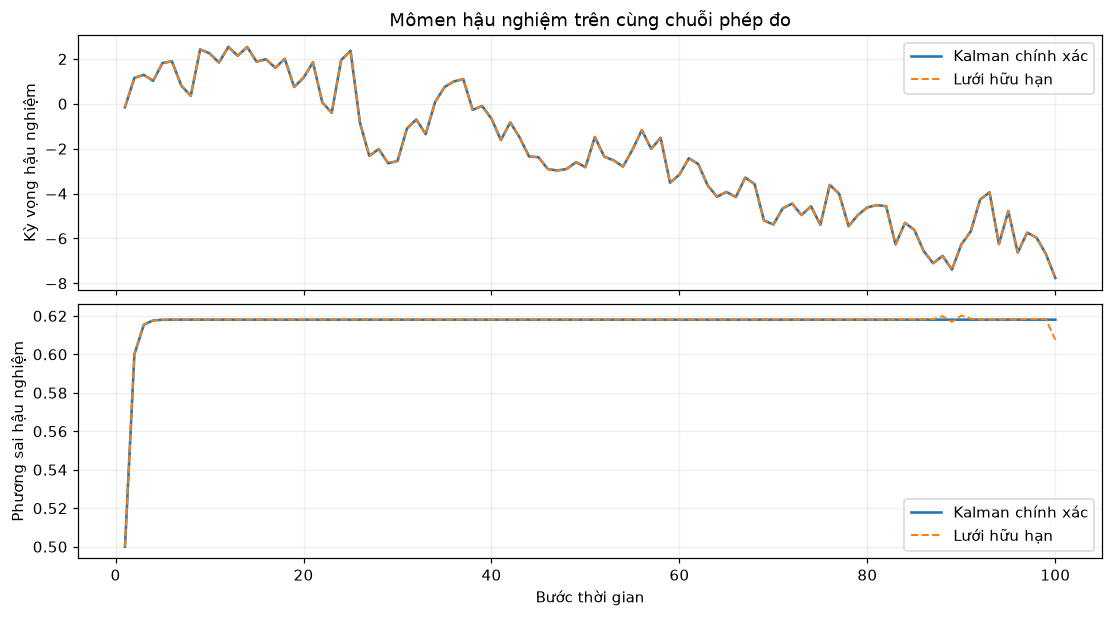

In [9]:
print(f"{'Phương pháp':<20} {'RMSE':>11} {'Dựng lưới (ms)':>15} {'Chạy lọc (ms)':>13}")
print(f"{'Kalman chính xác':<20} {walk_kf_rmse:11.6f} {'—':>15} {kalman_ms:13.3f}")
print(
    f"{'Lưới N = 1000':<20} {grid_main['rmse']:11.6f}"
    f" {grid_main['build_ms']:15.3f} {grid_main['filter_ms']:13.3f}"
)
print(f"Độ lệch tuyệt đối lớn nhất của kỳ vọng hậu nghiệm = {grid_main['max_mean_error']:.3e}")
print(f"Độ lệch tuyệt đối lớn nhất của phương sai hậu nghiệm = {grid_main['max_var_error']:.3e}")
print(f"TV lớn nhất trên các ô = {grid_main['max_tv']:.3e}")
print(f"Xác suất hậu nghiệm chính xác lớn nhất ngoài [-10, 10] = {grid_main['max_outside']:.3e}")

fig, axes = plt.subplots(2, 2, figsize=(9.5, 6), constrained_layout=True)
selected_steps = (1, 25, 50, 100)
for axis, k in zip(axes.flat, selected_steps):
    mean, sd = walk_mean[k - 1], np.sqrt(walk_var[k - 1])
    domain = np.linspace(mean - 4 * sd, mean + 4 * sd, 350)
    axis.plot(domain, norm.pdf(domain, loc=mean, scale=sd), lw=1.7, label="Kalman chính xác")
    axis.stairs(
        grid_main["masses"][k - 1] / grid_main["width"],
        grid_main["edges"], color="C1", ls="--", lw=1.5, label="Lưới hữu hạn",
    )
    axis.set(title=f"Hậu nghiệm tại k = {k}", xlabel="Trạng thái", ylabel="Mật độ xác suất")
    axis.set_xlim(domain[0], domain[-1])
    axis.legend()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, constrained_layout=True)
for axis, exact, approx, label in [
    (axes[0], walk_mean, grid_main["means"], "Kỳ vọng hậu nghiệm"),
    (axes[1], walk_var, grid_main["variances"], "Phương sai hậu nghiệm"),
]:
    axis.plot(walk_t, exact, lw=1.7, label="Kalman chính xác")
    axis.plot(walk_t, approx, "--", lw=1.3, label="Lưới hữu hạn")
    axis.set(ylabel=label)
    axis.legend()
axes[0].set_title("Mômen hậu nghiệm trên cùng chuỗi phép đo")
axes[1].set_xlabel("Bước thời gian")
plt.show()

### Thí nghiệm bổ sung về độ phân giải và hiệu ứng cắt miền

Thay đổi $N$ và giữ miền $[-10,10]$ để khảo sát sai số rời rạc hóa theo quy tắc trung điểm. Sau đó tăng gấp đôi độ rộng miền và số ô để giữ $h=0.02$, qua đó đo ảnh hưởng của việc dời biên. Xác suất hậu nghiệm chính xác nằm ngoài miền cho biết mức độ ảnh hưởng của biên. Chênh lệch mômen còn có thể do xác suất chuyển tiếp đã bị loại gần biên ở những bước trước. Bảng lấy giá trị lớn nhất theo thời gian cho độ lệch tuyệt đối của các mômen, TV và xác suất ngoài miền.

In [10]:
grid_trials = [
    (-10, 10, 10), (-10, 10, 20), (-10, 10, 50), (-10, 10, 100),
    (-10, 10, 1000), (-20, 20, 2000),
]
print(
    f"{'Miền':<12} {'N':>5} {'h':>7} {'Lệch kỳ vọng':>16} {'Lệch phương sai':>20}"
    f" {'TV lớn nhất':>15} {'Xác suất ngoài miền':>20} {'Dựng lưới (ms)':>15} {'Chạy lọc (ms)':>15}"
)
for lower, upper, n in grid_trials:
    result = grid_main if (lower, upper, n) == (-10, 10, 1000) else grid_comparison(lower, upper, n)
    if (lower, upper, n) == (-20, 20, 2000):
        grid_wide = result
    print(
        f"{f'[{lower}, {upper}]':<12} {n:5d} {result['width']:7.3f}"
        f" {result['max_mean_error']:16.3e} {result['max_var_error']:20.3e}"
        f" {result['max_tv']:15.3e} {result['max_outside']:20.3e}"
        f" {result['build_ms']:15.3f} {result['filter_ms']:15.3f}"
    )

assert grid_main["max_mean_error"] < 0.05 and grid_main["max_var_error"] < 0.05
assert grid_main["max_tv"] < 0.02
np.testing.assert_allclose(grid_wide["means"], walk_mean, rtol=0, atol=1e-8)
np.testing.assert_allclose(grid_wide["variances"], walk_var, rtol=0, atol=1e-8)

Miền             N       h     Lệch kỳ vọng      Lệch phương sai     TV lớn nhất  Xác suất ngoài miền  Dựng lưới (ms)   Chạy lọc (ms)
[-10, 10]       10   2.000        3.885e-01            4.496e-01       2.018e-01            2.233e-03           0.075           0.782
[-10, 10]       20   1.000        4.645e-03            6.118e-03       3.555e-02            2.233e-03           0.063           0.794
[-10, 10]       50   0.400        5.287e-03            9.794e-03       6.403e-03            2.233e-03           0.090           0.843
[-10, 10]      100   0.200        5.385e-03            1.030e-02       3.965e-03            2.233e-03           0.175           0.997
[-10, 10]     1000   0.020        5.417e-03            1.047e-02       3.650e-03            2.233e-03          19.093          16.940


[-20, 20]     2000   0.020        1.776e-15            3.331e-16       1.613e-05            6.445e-55          74.321         174.185


### Nhận xét

Lưới thô tạo ra sai số do tích phân theo quy tắc trung điểm và do biểu diễn phân phối bằng các ô. Khi giữ nguyên miền và làm mịn lưới, TV giảm, còn sai số mômen tiến tới một mức gần như cố định. Trên lưới thô, sai số mômen do rời rạc hóa có thể bù một phần độ chệch do cắt miền. Lưới mịn làm tăng thời gian chạy và bộ nhớ của ma trận chuyển tiếp đặc. Khi giữ nguyên độ rộng ô và mở rộng miền, kỳ vọng và phương sai khớp với Kalman đến mức sai số dấu phẩy động trong lần chạy này. TV vẫn phát hiện được chênh lệch giữa khối lượng xấp xỉ tại trung điểm và khối lượng Gaussian tích phân chính xác trên từng ô. Mức độ khớp trên miền đề xuất phụ thuộc vào chuỗi phép đo, vì bước đi ngẫu nhiên Gaussian có thể vượt ra ngoài bất kỳ khoảng hữu hạn nào.

## Tổng kết chương

Hai bước dự báo và cập nhật Bayes cho công thức truy hồi hữu hạn chiều chính xác khi mô hình tuyến tính Gaussian hoặc khi không gian trạng thái hữu hạn. Phương trình Riccati của bước đi ngẫu nhiên kết nối lọc Bayes với bộ lọc số thông thấp. Phân phối hậu nghiệm Gaussian chính xác của mô hình này cũng là chuẩn để đo riêng sai số rời rạc hóa và ảnh hưởng của miền hữu hạn.

In [11]:
display(Markdown(f"""
| Bài | Bài toán | Cơ chế toán học | Loại nghiệm | Kết quả tính toán | Ý nghĩa phương pháp |
|---|---|---|---|---|---|
| 6.1 | Mô hình Gaussian tuyến tính với nhiễu có kỳ vọng khác không | Trừ kỳ vọng nhiễu và áp dụng mô hình Gaussian affine | Chính xác | Lời giải giải tích | Các số hạng tất định đi vào kỳ vọng dự báo và sai số dự báo phép đo |
| 6.2 | Bước đi ngẫu nhiên Gaussian vô hướng | Lấy điều kiện trong phân phối Gaussian và dự báo phương sai | Chính xác | RMSE từ {walk_raw_rmse:.4f} giảm xuống {walk_kf_rmse:.4f} | Cập nhật độ bất định và trọng số của phép đo theo thời gian |
| 6.3 | Bộ ước lượng bước đi ngẫu nhiên ở trạng thái xác lập | Điểm bất động Riccati và biến đổi Z | Giới hạn xác lập chính xác | Hệ số Kalman giới hạn {steady_gain:.6f} | Tương ứng với bộ lọc thông thấp IIR bậc một |
| 6.4 | Hệ dao động chỉ đo trực tiếp một thành phần | Liên kết động lực học và hiệp phương sai chéo dự báo | Bộ lọc Gaussian chính xác | RMSE gộp từ {res_baseline_pooled:.4f} giảm xuống {res_kf_pooled:.4f} | Chuỗi phép đo vô hướng cung cấp thông tin về cả hai thành phần |
| 6.5 | Phân loại trạng thái của HMM nhị phân | Dự báo rời rạc, chuẩn hóa Bayes và MAP biên | Bộ lọc rời rạc chính xác | Sai số trung bình từ {hmm_baseline_error:.2%} giảm xuống {hmm_map_error:.2%} | Tính bền của trạng thái giúp cải thiện quyết định phân loại |
| 6.6 | Xấp xỉ trạng thái liên tục trên lưới | Quy tắc trung điểm và ma trận chuyển tiếp trên miền hữu hạn | Xấp xỉ, đối chiếu với Kalman chính xác | RMSE của lưới {grid_main['rmse']:.6f}, TV lớn nhất trên các ô {grid_main['max_tv']:.2e} | Có thể đo riêng ảnh hưởng của độ phân giải và việc cắt miền |
"""))


| Bài | Bài toán | Cơ chế toán học | Loại nghiệm | Kết quả tính toán | Ý nghĩa phương pháp |
|---|---|---|---|---|---|
| 6.1 | Mô hình Gaussian tuyến tính với nhiễu có kỳ vọng khác không | Trừ kỳ vọng nhiễu và áp dụng mô hình Gaussian affine | Chính xác | Lời giải giải tích | Các số hạng tất định đi vào kỳ vọng dự báo và sai số dự báo phép đo |
| 6.2 | Bước đi ngẫu nhiên Gaussian vô hướng | Lấy điều kiện trong phân phối Gaussian và dự báo phương sai | Chính xác | RMSE từ 0.9948 giảm xuống 0.7206 | Cập nhật độ bất định và trọng số của phép đo theo thời gian |
| 6.3 | Bộ ước lượng bước đi ngẫu nhiên ở trạng thái xác lập | Điểm bất động Riccati và biến đổi Z | Giới hạn xác lập chính xác | Hệ số Kalman giới hạn 0.618034 | Tương ứng với bộ lọc thông thấp IIR bậc một |
| 6.4 | Hệ dao động chỉ đo trực tiếp một thành phần | Liên kết động lực học và hiệp phương sai chéo dự báo | Bộ lọc Gaussian chính xác | RMSE gộp từ 0.4229 giảm xuống 0.2010 | Chuỗi phép đo vô hướng cung cấp thông tin về cả hai thành phần |
| 6.5 | Phân loại trạng thái của HMM nhị phân | Dự báo rời rạc, chuẩn hóa Bayes và MAP biên | Bộ lọc rời rạc chính xác | Sai số trung bình từ 30.24% giảm xuống 25.22% | Tính bền của trạng thái giúp cải thiện quyết định phân loại |
| 6.6 | Xấp xỉ trạng thái liên tục trên lưới | Quy tắc trung điểm và ma trận chuyển tiếp trên miền hữu hạn | Xấp xỉ, đối chiếu với Kalman chính xác | RMSE của lưới 0.720685, TV lớn nhất trên các ô 3.65e-03 | Có thể đo riêng ảnh hưởng của độ phân giải và việc cắt miền |
